# Modern GPT

GPT-2'nin (124M) üç parçasını modern karşılıklarıyla değiştiriyoruz ve her birinin doğrulama loss'una etkisini ölçüyoruz:

- **MLP:** GELU yerine SwiGLU
- **Normalizasyon:** LayerNorm yerine RMSNorm
- **Konum:** öğrenilen konum embedding'i (wpe) yerine RoPE

Veri, DataLoaderLite, optimizer ve eğitim döngüsü kurduğumu gpt2 modelindeki kodun aynısı. Her deney 120 adım, aynı veri ve aynı ayarlarla çalışıyor. T4'te bir deney yaklaşık 20 dakika sürdüğü için, 6 deney yaklaşık 2 saat sürdü. Raw model colabe kaydedilmiştir.

In [ ]:
# ARAŞTIRMA NOTLARI: neden bu üç parça?
#
# GPT-2 2019'da yazıldı. Bugünkü modellerin iskeleti aynı ama üç yeri değişmiş.
# Ben de bu üç yeri tek tek değiştirip doğrulama loss'una bakacağım.
#
# 1) GELU -> SwiGLU (MLP kısmı)
# MLP, her token'ı tek başına işleyen küçük bir sinir ağı. GPT-2'de aktivasyon GELU.
# SwiGLU'da giriş iki yola ayrılıyor, bir yol "kapı" gibi öbür yolu çarpıyor: silu(x @ W1) * (x @ W3).
# Yani ağ hangi bilginin geçeceğini kendisi öğreniyor. Shazeer (2020) bu tür kapılı çeşitlerin bazen
# ReLU ve GELU'dan daha iyi sonuç verdiğini yazmış. Matris sayısı 3 olduğu için gizli boyutu 2048 yaptım,
# böylece parametre sayısı yaklaşık aynı kalıyor.
#
# 2) LayerNorm -> RMSNorm
# LayerNorm ortalamayı çıkarıp ölçekliyor ve bias ekliyor. RMSNorm ortalamayı ve bias'ı bırakıyor,
# sadece büyüklüğe bölüyor. Zhang ve Sennrich (2019) benzer başarı ve %7-%64 daha kısa süre yazmış.
# Daha az iş yaptığı için seçtim.
#
# 3) Öğrenilen konum embedding'i (wpe) -> RoPE
# wpe, her pozisyon için öğrenilen bir vektör ve token'a ekleniyor. RoPE konumu eklemek yerine q ve k
# vektörlerini konuma göre döndürüyor, böylece attention skoru iki token arasındaki uzaklığa bağlı oluyor
# (kodda denedim, aynı uzaklık aynı skoru verdi). Su ve arkadaşları (2021) göreli konum bilgisini açıkça
# kattığını yazmış. Ayrıca wpe tablosu kalktığı için 786.432 parametre azalıyor.
#
# Başkaları ne bulmuş? GPT-2 124M'de üç parçayı tek tek ölçen bir deney bulamadım, bunlar dolaylı:
# - Küçük bir nanoGPT denemesinde (karakter seviyesinde Shakespeare, tek seed) üçü birlikte en düşük
#   loss'u vermiş (1,4645; baseline 1,5001). En büyük farkı RoPE yapmış, SwiGLU ve RMSNorm farkı gürültü kadar çıkmış.
# - GPT-2 124M ile FineWeb-Edu üzerinde bir blog denemesi üçünü birlikte denemiş: adım 2000'de 4,04
#   (klasik GPT-2 4,42). Tek tek ölçülmemiş.
# - PyTorch ekibi, RoPE karmaşık sayılarla yazılınca torch.compile'ın bozulduğunu, cos/sin ile yazınca
#   düzeldiğini yazmış. Benimki cos/sin kullanıyor.
#
# Beklentim: RoPE en çok fark yaratır, diğer ikisinin farkı küçük olabilir. Gürültüyü baseline_seed2 ile ölçeceğim.
# Sonuçlar gelince buraya gerçekte ne olduğunu yazacağım.
#
# Kaynaklar:
# RMSNorm: https://arxiv.org/abs/1910.07467
# SwiGLU: https://arxiv.org/abs/2002.05202
# RoPE: https://arxiv.org/abs/2104.09864
# nanoGPT'de üç parça denemesi: https://huggingface.co/Ridwan-1642/nanogpt-modernization-ckpts
# GPT-2'yi modernleştiren blog: https://vishsangale.github.io/notes/modernizing-gpt2/
# PyTorch blogu, RoPE ve compile: https://pytorch.org/blog/pytorch-compile-to-speed-up-inference/

In [1]:
%pip install -q tiktoken datasets

## 1. Veri: FineWeb-Edu

In [2]:
import os 
import multiprocessing as mp
import numpy as np 
import tiktoken
from datasets import load_dataset # pip install datasets
from tqdm import tqdm # pip install tqdm
import torch

In [3]:
local_dir = "edu_fineweb"
remote_name = "sample-10BT"
shard_size = int(1e7)   # shard başına 10M token
max_shards = 4          # 1 doğrulama + 3 eğitim ≈ 40M token

DATA_CACHE_DIR = os.path.join(os.getcwd(), local_dir)
os.makedirs(DATA_CACHE_DIR, exist_ok=True)

# streaming=True: tüm 10B token'ı indirmeden, belge belge okur
fw = load_dataset("HuggingFaceFW/fineweb-edu", name=remote_name, split="train", streaming=True)

enc = tiktoken.get_encoding("gpt2")
eot = enc._special_tokens["<|endoftext|>"] 

def tokenize(doc):
    tokens = [eot]
    tokens.extend(enc.encode_ordinary(doc["text"]))
    tokens_np = np.array(tokens)
    assert (0 <= tokens_np).all() and (tokens_np < 2**16).all(), "token dictionary too large for uint16"
    return tokens_np.astype(np.uint16)

def write_datafile(filename, tokens_np):
    np.save(filename, tokens_np)

nprocs = max(1, os.cpu_count() // 2)
with mp.Pool(nprocs) as pool:
    shard_index = 0
    all_tokens_np = np.empty((shard_size,), dtype=np.uint16)
    token_count = 0
    progress_bar = None
    for tokens in pool.imap(tokenize, fw, chunksize=16):
        if token_count + len(tokens) < shard_size:
            all_tokens_np[token_count:token_count + len(tokens)] = tokens
            token_count += len(tokens)
            if progress_bar is None:
                progress_bar = tqdm(total=shard_size, unit="tokens", desc=f"Shard {shard_index}")
            progress_bar.update(len(tokens))
        else:
            split = "val" if shard_index == 0 else "train"
            filename = os.path.join(DATA_CACHE_DIR, f"edufineweb_{split}_{shard_index:06d}")
            remainder = shard_size - token_count
            if progress_bar is None:
                progress_bar = tqdm(total=shard_size, unit="tokens", desc=f"Shard {shard_index}")
            progress_bar.update(remainder)
            all_tokens_np[token_count:token_count + remainder] = tokens[:remainder]
            write_datafile(filename, all_tokens_np)
            shard_index += 1
            progress_bar = None
            if shard_index >= max_shards:      
                break
            all_tokens_np[0:len(tokens) - remainder] = tokens[remainder:]
            token_count = len(tokens) - remainder

    if token_count != 0 and shard_index < max_shards:
        split = "val" if shard_index == 0 else "train"
        filename = os.path.join(DATA_CACHE_DIR, f"edufineweb_{split}_{shard_index:06d}")
        write_datafile(filename, all_tokens_np[:token_count])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/26.4k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/2410 [00:00<?, ?it/s]

Shard 3: 100%|█████████▉| 9999193/10000000 [00:08<00:00, 1138959.41tokens/s]


## 2. DataLoaderLite

In [4]:
def load_tokens(filename):
    npt = np.load(filename)
    npt = npt.astype(np.int32) # added after video
    ptt = torch.tensor(npt, dtype=torch.long)
    return ptt

class DataLoaderLite:
    def __init__(self, B, T, process_rank, num_processes, split):
        self.B = B
        self.T = T
        self.process_rank = process_rank
        self.num_processes = num_processes
        assert split in {'train', 'val'}

        # get the shard filenames
        data_root = "edu_fineweb"
        shards = os.listdir(data_root)
        shards = [s for s in shards if split in s]
        shards = sorted(shards)
        shards = [os.path.join(data_root, s) for s in shards]
        self.shards = shards
        assert len(shards) > 0, f"no shards found for split {split}"
        if master_process:
            print(f"found {len(shards)} shards for split {split}")
        self.reset()

    def reset(self):
        # state, init at shard zero
        self.current_shard = 0
        self.tokens = load_tokens(self.shards[self.current_shard])
        self.current_position = self.B * self.T * self.process_rank

    def next_batch(self):
        B, T = self.B, self.T
        buf = self.tokens[self.current_position : self.current_position+B*T+1]
        x = (buf[:-1]).view(B, T) # inputs
        y = (buf[1:]).view(B, T) # targets
        # advance the position in the tensor
        self.current_position += B * T * self.num_processes
        # if loading the next batch would be out of bounds, advance to next shard
        if self.current_position + (B * T * self.num_processes + 1) > len(self.tokens):
            self.current_shard = (self.current_shard + 1) % len(self.shards)
            self.tokens = load_tokens(self.shards[self.current_shard])
            self.current_position = B * T * self.process_rank
        return x, y

## 3. Model: GPT-2 ve üç modern parça

In [ ]:
import os
import math
import time
import inspect
from dataclasses import dataclass
import torch
import torch.nn as nn
from torch.nn import functional as F

# -----------------------------------------------------------------------------
# GPT-2'nin kodu, üç parça ayrı ayrı açılıp kapanabiliyor:
#   use_swiglu  : MLP'de GELU yerine SwiGLU
#   use_rmsnorm : LayerNorm yerine RMSNorm
#   use_rope    : öğrenilen konum embedding'i (wpe) yerine RoPE
# Üçü de False ise bu birebir GPT-2 demektir. 

class RMSNorm(nn.Module):
    # LayerNorm'dan farkı: ortalamayı çıkarmaz, bias yok, sadece karekök-ortalama-karesine böler
    def __init__(self, dim, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

def precompute_rope(head_size, block_size, base=10000.0):
   
    inv_freq = 1.0 / (base ** (torch.arange(0, head_size, 2).float() / head_size)) # (hs/2)
    t = torch.arange(block_size).float() # (block_size)
    freqs = torch.outer(t, inv_freq) # (block_size, hs/2)
    return freqs.cos(), freqs.sin()

def apply_rope(x, cos, sin):
  
    T = x.size(2)
    cos, sin = cos[:T], sin[:T] # (T, hs/2)
    x1, x2 = x.chunk(2, dim=-1)
    return torch.cat((x1 * cos - x2 * sin, x2 * cos + x1 * sin), dim=-1)

class CausalSelfAttention(nn.Module):

    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        # key, query, value projections for all heads, but in a batch
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        # output projection
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1
        # regularization
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        self.use_rope = config.use_rope
        if config.use_rope:
            cos, sin = precompute_rope(config.n_embd // config.n_head, config.block_size)
            self.register_buffer("rope_cos", cos, persistent=False)
            self.register_buffer("rope_sin", sin, persistent=False)

    def forward(self, x):
        B, T, C = x.size() # batch size, sequence length, embedding dimensionality (n_embd)
        # calculate query, key, values for all heads in batch and move head forward to be the batch dim
        # nh is "number of heads", hs is "head size", and C (number of channels) = nh * hs
        qkv = self.c_attn(x)
        q, k, v = qkv.split(self.n_embd, dim=2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
        if self.use_rope:
         
            q = apply_rope(q, self.rope_cos, self.rope_sin)
            k = apply_rope(k, self.rope_cos, self.rope_sin)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True) # flash attention
        y = y.transpose(1, 2).contiguous().view(B, T, C) # re-assemble all head outputs side by side
        # output projection
        y = self.c_proj(y)
        return y

class MLP(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.use_swiglu = config.use_swiglu
        if config.use_swiglu:
           
            hidden = int(8 * config.n_embd / 3)
            hidden = 64 * ((hidden + 63) // 64) # 64'ün katına yuvarla
            self.c_fc = nn.Linear(config.n_embd, hidden, bias=False) # kapı
            self.c_fc2 = nn.Linear(config.n_embd, hidden, bias=False) # değer
            self.c_proj = nn.Linear(hidden, config.n_embd, bias=False)
        else:
            self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd)
            self.gelu = nn.GELU(approximate='tanh')
            self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1

    def forward(self, x):
        if self.use_swiglu:
            return self.c_proj(F.silu(self.c_fc(x)) * self.c_fc2(x))
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x

class Block(nn.Module):

    def __init__(self, config):
        super().__init__()
        Norm = RMSNorm if config.use_rmsnorm else nn.LayerNorm
        self.ln_1 = Norm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = Norm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x

@dataclass
class GPTConfig:
    block_size: int = 1024 # max sequence length
    vocab_size: int = 50257 # number of tokens: 50,000 BPE merges + 256 bytes tokens + 1 <|endoftext|> token
    n_layer: int = 12 # number of layers
    n_head: int = 12 # number of heads
    n_embd: int = 768 # embedding dimension
    use_swiglu: bool = False
    use_rmsnorm: bool = False
    use_rope: bool = False

class GPT(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.config = config
        Norm = RMSNorm if config.use_rmsnorm else nn.LayerNorm

        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = Norm(config.n_embd),
        ))
        if not config.use_rope:
            self.transformer.wpe = nn.Embedding(config.block_size, config.n_embd) 
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)

        # weight sharing scheme
        self.transformer.wte.weight = self.lm_head.weight

        # init params
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            std = 0.02
            if hasattr(module, 'NANOGPT_SCALE_INIT'):
                std *= (2 * self.config.n_layer) ** -0.5
            torch.nn.init.normal_(module.weight, mean=0.0, std=std)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        # idx is of shape (B, T)
        B, T = idx.size()
        assert T <= self.config.block_size, f"Cannot forward sequence of length {T}, block size is only {self.config.block_size}"
        # forward the token and posisition embeddings
        x = self.transformer.wte(idx) # token embeddings of shape (B, T, n_embd)
        if not self.config.use_rope:
            pos = torch.arange(0, T, dtype=torch.long, device=idx.device) # shape (T)
            x = x + self.transformer.wpe(pos) # position embeddings of shape (T, n_embd)
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layernorm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x) # (B, T, vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    def configure_optimizers(self, weight_decay, learning_rate, device_type):
        # start with all of the candidate parameters (that require grad)
        param_dict = {pn: p for pn, p in self.named_parameters()}
        param_dict = {pn: p for pn, p in param_dict.items() if p.requires_grad}
        # create optim groups. Any parameters that is 2D will be weight decayed, otherwise no.
        # i.e. all weight tensors in matmuls + embeddings decay, all biases and layernorms don't.
        decay_params = [p for n, p in param_dict.items() if p.dim() >= 2]
        nodecay_params = [p for n, p in param_dict.items() if p.dim() < 2]
        optim_groups = [
            {'params': decay_params, 'weight_decay': weight_decay},
            {'params': nodecay_params, 'weight_decay': 0.0}
        ]
        num_decay_params = sum(p.numel() for p in decay_params)
        num_nodecay_params = sum(p.numel() for p in nodecay_params)
        print(f"num decayed parameter tensors: {len(decay_params)}, with {num_decay_params:,} parameters")
        print(f"num non-decayed parameter tensors: {len(nodecay_params)}, with {num_nodecay_params:,} parameters")
        # Create AdamW optimizer and use the fused version if it is available
        fused_available = 'fused' in inspect.signature(torch.optim.AdamW).parameters
        use_fused = fused_available and device_type == "cuda"
        print(f"using fused AdamW: {use_fused}")
        optimizer = torch.optim.AdamW(optim_groups, lr=learning_rate, betas=(0.9, 0.95), eps=1e-8, fused=use_fused)
        return optimizer

## 4. Deneyler

In [ ]:
# Deneyler: aynı model boyutu, aynı veri, aynı adım sayısı ile her seferinde tek parça değişiyor.
model_args = dict(block_size=1024, vocab_size=50304, n_layer=12, n_head=12, n_embd=768)

experiments = {
    "baseline":      dict(),                                                    # GPT-2'nin kendisi
    "swiglu":        dict(use_swiglu=True),                                     # GELU -> SwiGLU
    "rmsnorm":       dict(use_rmsnorm=True),                                    # LayerNorm -> RMSNorm
    "rope":          dict(use_rope=True),                                       # wpe -> RoPE
    "hepsi":         dict(use_swiglu=True, use_rmsnorm=True, use_rope=True),    # üçü birlikte
    "baseline_seed2": dict(seed=42),                                            # gürültü payı için başka bir seed ile tekrarladım
}
run_names = list(experiments)

In [ ]:
# parametre sayıları: her parça değişince model ne kadar küçülüyor / büyüyor?
for name, flags in experiments.items():
    flags = {k: v for k, v in flags.items() if k != "seed"}
    n = sum(p.numel() for p in GPT(GPTConfig(**model_args, **flags)).parameters())
    print(f"{name:15s} {n:>12,} parametre")

baseline         124,475,904 parametre
swiglu           124,429,824 parametre
rmsnorm          124,456,704 parametre
rope             123,689,472 parametre
hepsi            123,624,192 parametre
baseline_seed2   124,475,904 parametre


## 5. Eğitim

In [ ]:
import gc
import json
import tiktoken
import torch.nn.functional as F

# -----------------------------------------------------------------------------
# DDP'siz tek GPU ile, T4 için uyarlanmış halidir. Aynı döngü, 6 deney için bir fonksiyonun içinde yapılır.

ddp_rank = 0
ddp_world_size = 1
master_process = True # this process will do logging, checkpointing etc.

# attempt to autodetect device
device = "cpu"
if torch.cuda.is_available():
    device = "cuda"
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = "mps"
print(f"using device: {device}")

# added after video, pytorch can be serious about it's device vs. device_type distinction
device_type = "cuda" if device.startswith("cuda") else "cpu"

enc = tiktoken.get_encoding("gpt2")

total_batch_size = 32768 
B = 4 # micro batch size. 
T = 1024 # sequence length
assert total_batch_size % (B * T * ddp_world_size) == 0, "make sure total_batch_size is divisible by B * T * ddp_world_size"
grad_accum_steps = total_batch_size // (B * T * ddp_world_size)
if master_process:
    print(f"total desired batch size: {total_batch_size}")
    print(f"=> calculated gradient accumulation steps: {grad_accum_steps}")

use_compile = False 

max_lr = 6e-4
min_lr = max_lr * 0.1
warmup_steps = 5 # 
max_steps = 120 
val_interval = 20 

def get_lr(it):
    # 1) linear warmup for warmup_iters steps
    if it < warmup_steps:
        return max_lr * (it+1) / warmup_steps
    # 2) if it > lr_decay_iters, return min learning rate
    if it > max_steps:
        return min_lr
    # 3) in between, use cosine decay down to min learning rate
    decay_ratio = (it - warmup_steps) / (max_steps - warmup_steps)
    assert 0 <= decay_ratio <= 1
    coeff = 0.5 * (1.0 + math.cos(math.pi * decay_ratio)) # coeff starts at 1 and goes to 0
    return min_lr + coeff * (max_lr - min_lr)

def run_experiment(name, flags):
    flags = dict(flags)
    seed = flags.pop("seed", 1337)
    torch._dynamo.reset() 
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)

    train_loader = DataLoaderLite(B=B, T=T, process_rank=ddp_rank, num_processes=ddp_world_size, split="train")
    val_loader = DataLoaderLite(B=B, T=T, process_rank=ddp_rank, num_processes=ddp_world_size, split="val")

    # create model
    model = GPT(GPTConfig(**model_args, **flags))
    model.to(device)
    raw_model = model # always contains the "raw" unwrapped model
    if use_compile:
        model = torch.compile(model)
    num_params = sum(p.numel() for p in raw_model.parameters())
    print(f"=== {name}: {num_params:,} parametre, ayarlar: {flags}, seed: {seed}")

    # optimize!
    optimizer = raw_model.configure_optimizers(weight_decay=0.1, learning_rate=6e-4, device_type=device_type)

    log = {"train": [], "val": []}
    samples = []
    train_time = 0.0

    for step in range(max_steps):
        t0 = time.time()
        last_step = (step == max_steps - 1)

        # once in a while evaluate our validation loss
        if step % val_interval == 0 or last_step:
            model.eval()
            val_loader.reset()
            with torch.no_grad():
                val_loss_accum = 0.0
                val_loss_steps = 20
                for _ in range(val_loss_steps):
                    x, y = val_loader.next_batch()
                    x, y = x.to(device), y.to(device)
                    logits, loss = model(x, y)
                    loss = loss / val_loss_steps
                    val_loss_accum += loss.detach()
            if master_process:
                print(f"{name} | validation loss: {val_loss_accum.item():.4f}")
                log["val"].append((step, val_loss_accum.item()))

        # once in a while generate from the model (T4: sadece son adımda)
        if last_step:
            model.eval()
            num_return_sequences = 4
            max_length = 32
            tokens = enc.encode("Hello, I'm a language model,")
            tokens = torch.tensor(tokens, dtype=torch.long)
            tokens = tokens.unsqueeze(0).repeat(num_return_sequences, 1)
            xgen = tokens.to(device)
            sample_rng = torch.Generator(device=device)
            sample_rng.manual_seed(42 + ddp_rank)
            while xgen.size(1) < max_length:
                # forward the model to get the logits
                with torch.no_grad():
                    logits, loss = raw_model(xgen) # (B, T, vocab_size)
                    # take the logits at the last position
                    logits = logits[:, -1, :] # (B, vocab_size)
                    # get the probabilities
                    probs = F.softmax(logits, dim=-1)
                    # do top-k sampling of 50 (huggingface pipeline default)
                    # topk_probs here becomes (5, 50), topk_indices is (5, 50)
                    topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
                    # select a token from the top-k probabilities
                    # note: multinomial does not demand the input to sum to 1
                    ix = torch.multinomial(topk_probs, 1, generator=sample_rng) # (B, 1)
                    # gather the corresponding indices
                    xcol = torch.gather(topk_indices, -1, ix) # (B, 1)
                    # append to the sequence
                    xgen = torch.cat((xgen, xcol), dim=1)
            # print the generated text
            for i in range(num_return_sequences):
                tokens = xgen[i, :max_length].tolist()
                decoded = enc.decode([t for t in tokens if t < enc.n_vocab]) # T4: vocab 50304'e yuvarlandı, fazladan id'lerin tokenı yok
                print(f"{name} | rank {ddp_rank} sample {i}: {decoded}")
                samples.append(decoded)

        # do one step of the optimization
        model.train()
        optimizer.zero_grad()
        loss_accum = 0.0
        for micro_step in range(grad_accum_steps):
            x, y = train_loader.next_batch()
            x, y = x.to(device), y.to(device)
            logits, loss = model(x, y)
            # we have to scale the loss to account for gradient accumulation,
            # because the gradients just add on each successive backward().
            # addition of gradients corresponds to a SUM in the objective, but
            # instead of a SUM we want MEAN. Scale the loss here so it comes out right
            loss = loss / grad_accum_steps
            loss_accum += loss.detach()
            loss.backward()
        norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        # determine and set the learning rate for this iteration
        lr = get_lr(step)
        for param_group in optimizer.param_groups:
            param_group['lr'] = lr
        optimizer.step()
        if device_type == "cuda":
            torch.cuda.synchronize() # wait for the GPU to finish work
        t1 = time.time()
        dt = t1 - t0 # time difference in seconds
        tokens_processed = train_loader.B * train_loader.T * grad_accum_steps * ddp_world_size
        tokens_per_sec = tokens_processed / dt
        if step > 0:
            train_time += dt
        if master_process:
            log["train"].append((step, loss_accum.item()))
            if step % 10 == 0 or last_step: 
                print(f"{name} | step {step:5d} | loss: {loss_accum.item():.6f} | lr {lr:.4e} | norm: {norm:.4f} | dt: {dt*1000:.2f}ms | tok/sec: {tokens_per_sec:.2f}")

    result = {
        "num_params": num_params,
        "val": log["val"],
        "train": log["train"],
        "val_final": log["val"][-1][1],
        "tok_per_sec": (max_steps - 1) * B * T * grad_accum_steps / max(train_time, 1e-9),
        "samples": samples,
        "max_steps": max_steps,
    }
   
    del model, raw_model, optimizer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result

import shutil

drive_copy = "/content/drive/MyDrive/modern_results.json"
if not os.path.exists("modern_results.json") and os.path.exists(drive_copy):
    shutil.copy(drive_copy, "modern_results.json")
results = json.load(open("modern_results.json")) if os.path.exists("modern_results.json") else {}
stale = [k for k, v in results.items() if v.get("max_steps") != max_steps]
for k in stale:
    print(f"=== {k}: farklı adım sayısıyla koşulmuş, silinip yeniden koşulacak")
    del results[k]
for name in run_names:
    if name in results:
        print(f"=== {name}: daha önce bitmiş, atlanıyor (val loss {results[name]['val_final']:.4f})")
        continue
    results[name] = run_experiment(name, experiments[name])
    json.dump(results, open("modern_results.json", "w")) 
    if os.path.isdir("/content/drive/MyDrive"):
        shutil.copy("modern_results.json", drive_copy)

using device: cuda
total desired batch size: 32768
=> calculated gradient accumulation steps: 8
found 3 shards for split train
found 1 shards for split val
=== baseline: 124,475,904 parametre, ayarlar: {}, seed: 1337
num decayed parameter tensors: 50, with 124,354,560 parameters
num non-decayed parameter tensors: 98, with 121,344 parameters
using fused AdamW: True
baseline | validation loss: 11.0216
baseline | step     0 | loss: 11.025677 | lr 1.2000e-04 | norm: 15.4882 | dt: 13734.79ms | tok/sec: 2385.77
baseline | step    10 | loss: 7.882631 | lr 5.9749e-04 | norm: 0.7152 | dt: 8436.27ms | tok/sec: 3884.18
baseline | validation loss: 7.6419
baseline | step    20 | loss: 7.676212 | lr 5.7765e-04 | norm: 0.8177 | dt: 15104.82ms | tok/sec: 2169.37
baseline | step    30 | loss: 7.429316 | lr 5.3944e-04 | norm: 0.4709 | dt: 8430.16ms | tok/sec: 3887.00
baseline | validation loss: 7.3207
baseline | step    40 | loss: 7.326090 | lr 4.8570e-04 | norm: 0.6748 | dt: 15189.92ms | tok/sec: 2157.

## 6. Sonuç

         deney   parametre  son val loss  baseline'dan fark  tok/sn
      baseline 124,475,904        6.8673             0.0000    3747
        swiglu 124,429,824        6.8910             0.0237    3729
       rmsnorm 124,456,704        6.8726             0.0053    3640
          rope 123,689,472        6.7187            -0.1486    3631
         hepsi 123,624,192        6.7538            -0.1135    3539
baseline_seed2 124,475,904        6.8998             0.0325    3729

seed gürültüsü (baseline ile baseline_seed2 farkı): 0.0325
Bundan küçük farklar şansa bağlı olabilir.


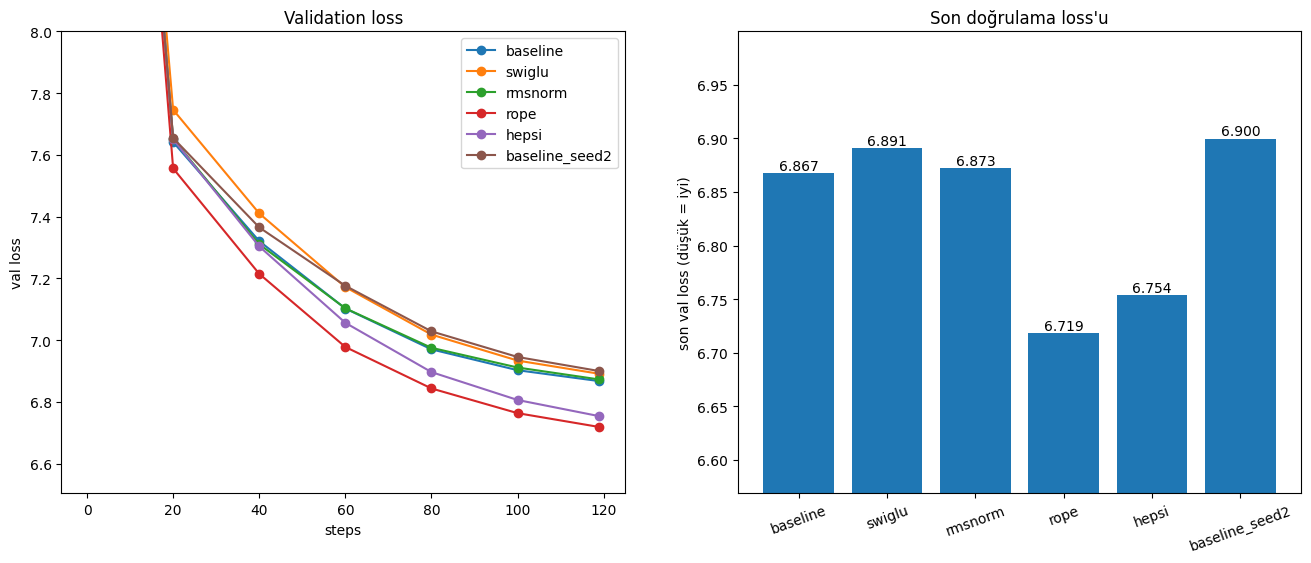

In [ ]:
import json
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline


if "results" not in globals() or not results:
    results = json.load(open("modern_results.json"))

base = results["baseline"]["val_final"]
rows = []
for name, r in results.items():
    rows.append({
        "deney": name,
        "parametre": f"{r['num_params']:,}",
        "son val loss": round(r["val_final"], 4),
        "baseline'dan fark": round(r["val_final"] - base, 4),
        "tok/sn": round(r["tok_per_sec"]),
    })
df = pd.DataFrame(rows)
print(df.to_string(index=False))


if "baseline_seed2" in results:
    noise = abs(results["baseline_seed2"]["val_final"] - base)
    print(f"\nseed gürültüsü (baseline ile baseline_seed2 farkı): {noise:.4f}")
    print("Bundan küçük farklar şansa bağlı olabilir.")

plt.figure(figsize=(16, 6))

# Validation loss ile tüm deneyler aynı grafikte gösterimi
plt.subplot(121)
for name, r in results.items():
    xs, ys = zip(*r["val"])
    plt.plot(xs, ys, marker="o", label=name)
plt.xlabel("steps")
plt.ylabel("val loss")
plt.ylim(top=8.0)
plt.legend()
plt.title("Validation loss")

plt.subplot(122)
names = list(results)
vals = [results[n]["val_final"] for n in names]
bars = plt.bar(names, vals)
plt.ylim(min(vals) - 0.15, max(vals) + 0.1)
for b, v in zip(bars, vals):
    plt.text(b.get_x() + b.get_width() / 2, v, f"{v:.3f}", ha="center", va="bottom")
plt.xticks(rotation=20)
plt.ylabel("son val loss (düşük = iyi)")
plt.title("Son doğrulama loss'u")
plt.show()

## Yorum

(Sonuçlar gelince kendi cümlelerinle yaz: hangi parça en çok fark etti, fark seed gürültüsünden büyük mü?)